# 03. IPCA: Validação da Decomposição por Subitens



## Parte 0 _ Subitem → Item → Subgrupo → Grupo → IPCA

Os notebooks anteriores analisaram individualmente a estrutura do IPCA:

- `02.ipca` $\to$ IPCA geral
- `02.01.grupos` $\to$ grupos
- `02.02.subgrupos` $\to$ subgrupos
- `02.03.itens` $\to$ itens
- `02.04.subitens` $\to$ subitens

Neste notebook utilizaremos os **subitens como origem única da
reconstrução**.

A pergunta central é:

> Partindo das variações e dos pesos publicados para os subitens,
> conseguimos reproduzir os níveis superiores da hierarquia e,
> finalmente, o IPCA geral?

A validação será:

```text
                     SUBITENS
                        |
           +------------+------------+
           |            |            |
           v            v            v
         ITENS      SUBGRUPOS      GRUPOS
           |            |            |
           +------------+------------+
                        |
                        v
                    IPCA GERAL
```

Portanto, testaremos:

1. `subitem → item`
2. `subitem → subgrupo`
3. `subitem → grupo`
4. `subitem → IPCA`

Este notebook NÃO executa pipelines e NÃO altera o banco de dados.

### 1. Estrutura matemática

Seja $\pi_{i,t}$ a variação mensal do subitem $i$ no período $t$.

Seja $w_{i,t}$ seu peso publicado.

A contribuição aproximada do subitem é:

$$
C_{i,t}=\pi_{i,t}\frac{w_{i,t}}{100}
$$

onde $C_{i,t}$ é expresso aproximadamente em pontos percentuais.

A contribuição mantém o sinal:

$$
C_{i,t}>0
$$

representa contribuição positiva e:

$$
C_{i,t}<0
$$

representa contribuição negativa.

#### 1.1 Subitem → Item

Para um item $j$, somamos as contribuições de todos os subitens
pertencentes ao item:

$$
\widehat{C}_{j,t}^{SI}=\sum_{i \in j} C_{i,t}
$$

O valor reconstruído é comparado à contribuição calculada com
`indice` e `peso` publicados para o próprio item.

#### 1.2 Subitem → Subgrupo

Para um subgrupo $s$:

$$
\widehat{C}_{s,t}^{SI}=\sum_{i \in s} C_{i,t}
$$

Não utilizamos o item publicado como etapa intermediária.

A origem continua sendo exclusivamente o nível de subitem.

#### 1.3 Subitem → Grupo

Para um grupo $g$:

$$
\widehat{C}_{g,t}^{SI}=\sum_{i \in g} C_{i,t}
$$

#### 1.4 Subitem → IPCA

Finalmente:

$$
\widehat{\pi}^{SI}_t=\sum_i C_{i,t}
$$

e comparamos com o IPCA geral publicado:

$$
\pi_t
$$

#### 1.5 Erro de reconstrução

Para cada validação:

$$
\varepsilon=valor_{reconstruído}-valor_{publicado}
$$

e:

$$
E=|\varepsilon|
$$

Erros pequenos indicam elevada consistência entre os subitens e
o nível agregado analisado.

### 2. Configuração do ambiente

In [85]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /home/moacir/projects/ml/analytics/inflation


### 3. Importações

In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.database.connection import engine

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.6f}".format)

### 4. Função de preparação

Os quatro níveis possuem a mesma estrutura básica:

```text
date
categoria
categoria_nome
indice
peso
```

Calculamos a contribuição:

$$
C_{i,t}=\pi_{i,t}\frac{w_{i,t}}{100}
$$

In [87]:
def preparar_nivel(df):
    """
    Padroniza datas e categorias e calcula a
    contribuição de cada componente.
    """

    df = df.copy()

    df["date"] = pd.to_datetime(
        df["date"]
    )

    df["categoria"] = (
        df["categoria"]
        .astype(str)
    )

    df = (
        df
        .sort_values(
            [
                "date",
                "categoria",
            ]
        )
        .reset_index(drop=True)
    )

    df["contribuicao"] = (
        df["indice"]
        * df["peso"]
        / 100
    )

    return df

---

## PARTE I: CARREGAMENTO



### 5. IPCA geral

In [88]:
ipca = pd.read_sql(
    """
    SELECT
        date,
        indice
    FROM bcb.ipca_geral
    ORDER BY date;
    """,
    engine,
)

ipca["date"] = pd.to_datetime(
    ipca["date"]
)

ipca = (
    ipca
    .sort_values("date")
    .reset_index(drop=True)
)

### 6. Grupos

In [89]:
grupos = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_grupos
    ORDER BY date, categoria;
    """,
    engine,
)

grupos = preparar_nivel(
    grupos
)

### 7. Subgrupos

In [90]:
subgrupos = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_subgrupos
    ORDER BY date, categoria;
    """,
    engine,
)

subgrupos = preparar_nivel(
    subgrupos
)

### 8. Itens

In [91]:
itens = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_itens
    ORDER BY date, categoria;
    """,
    engine,
)

itens = preparar_nivel(
    itens
)

### 9. Subitens

In [92]:
subitens = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_subitens
    ORDER BY date, categoria;
    """,
    engine,
)

subitens = preparar_nivel(
    subitens
)

### 10. Construir chaves hierárquicas

A estrutura utilizada pelo projeto é:

```text
grupo      -> 1 dígito
subgrupo   -> 2 dígitos
item       -> 4 dígitos
subitem    -> 7 dígitos
```

Portanto os códigos-pai podem ser obtidos diretamente a partir
do código do subitem.

In [93]:
subitens["grupo_codigo"] = (
    subitens["categoria"]
    .str[:1]
)

subitens["subgrupo_codigo"] = (
    subitens["categoria"]
    .str[:2]
)

subitens["item_codigo"] = (
    subitens["categoria"]
    .str[:4]
)

### 11. Cobertura histórica

In [94]:
cobertura = pd.DataFrame(
    [
        {
            "nivel": "IPCA",
            "inicio": ipca["date"].min(),
            "fim": ipca["date"].max(),
            "observacoes": len(ipca),
        },
        {
            "nivel": "Grupos",
            "inicio": grupos["date"].min(),
            "fim": grupos["date"].max(),
            "observacoes": len(grupos),
        },
        {
            "nivel": "Subgrupos",
            "inicio": subgrupos["date"].min(),
            "fim": subgrupos["date"].max(),
            "observacoes": len(subgrupos),
        },
        {
            "nivel": "Itens",
            "inicio": itens["date"].min(),
            "fim": itens["date"].max(),
            "observacoes": len(itens),
        },
        {
            "nivel": "Subitens",
            "inicio": subitens["date"].min(),
            "fim": subitens["date"].max(),
            "observacoes": len(subitens),
        },
    ]
)

cobertura

,nivel,inicio,fim,observacoes
0,IPCA,1979-12-01,2026-08-01,561
1,Grupos,2020-01-01,2026-08-01,720
2,Subgrupos,2020-01-01,2026-08-01,1520
3,Itens,2020-01-01,2026-08-01,4080
4,Subitens,2020-01-01,2026-08-01,30160


---

## PARTE II: RECONSTRUÇÕES A PARTIR DOS SUBITENS



### 12. Subitem → Item

Para cada item:

$$
\widehat{C}_{j,t}^{SI}=\sum_{i \in j}C_{i,t}
$$

In [112]:
recon_itens = (
    subitens
    .groupby(
        [
            "date",
            "item_codigo",
        ],
        as_index=False,
    )["contribuicao"]
    .sum()
    .rename(
        columns={
            "contribuicao":
            "contribuicao_reconstruida"
        }
    )
)

itens_publicados = (
    itens[
        [
            "date",
            "categoria",
            "categoria_nome",
            "contribuicao",
        ]
    ]
    .rename(
        columns={
            "categoria":
            "item_codigo",
            "categoria_nome":
            "item_nome",
            "contribuicao":
            "contribuicao_publicada",
        }
    )
)

validacao_itens = (
    itens_publicados
    .merge(
        recon_itens,
        on=[
            "date",
            "item_codigo",
        ],
        how="inner",
        validate="one_to_one",
    )
)

validacao_itens["erro"] = (
    validacao_itens[
        "contribuicao_reconstruida"
    ]
    - validacao_itens[
        "contribuicao_publicada"
    ]
)

validacao_itens["erro_abs"] = (
    validacao_itens["erro"]
    .abs()
)

validacao_itens.tail(15)

,date,item_codigo,item_nome,contribuicao_publicada,contribuicao_reconstruida,erro,erro_abs
4065,2026-08-01,5104,Combustíveis (veículos),-0.055358,-0.055226,0.000132,0.000132
4066,2026-08-01,6101,Produtos farmacêuticos,0.007290,0.007268,-0.000021,0.000021
4067,2026-08-01,6102,Produtos óticos,0.003902,0.003902,0.000000,0.000000
4068,2026-08-01,6201,Serviços médicos e dentários,0.006187,0.006236,0.000049,0.000049
4069,2026-08-01,6202,Serviços laboratoriais e hospitalares,-0.000899,-0.000885,0.000014,0.000014
4070,2026-08-01,6203,Plano de saúde,0.017390,0.017390,0.000000,0.000000
4071,2026-08-01,6301,Higiene pessoal,-0.001641,-0.001644,-0.000003,0.000003
4072,2026-08-01,7101,Serviços pessoais,0.023494,0.023272,-0.000222,0.000222
4073,2026-08-01,7201,Recreação,-0.003977,-0.003865,0.000112,0.000112
4074,2026-08-01,7202,Fumo,0.113328,0.113328,0.000000,0.000000


### 13. Subitem → Subgrupo

In [96]:
recon_subgrupos = (
    subitens
    .groupby(
        [
            "date",
            "subgrupo_codigo",
        ],
        as_index=False,
    )["contribuicao"]
    .sum()
    .rename(
        columns={
            "contribuicao":
            "contribuicao_reconstruida"
        }
    )
)

subgrupos_publicados = (
    subgrupos[
        [
            "date",
            "categoria",
            "categoria_nome",
            "contribuicao",
        ]
    ]
    .rename(
        columns={
            "categoria":
            "subgrupo_codigo",
            "categoria_nome":
            "subgrupo_nome",
            "contribuicao":
            "contribuicao_publicada",
        }
    )
)

validacao_subgrupos = (
    subgrupos_publicados
    .merge(
        recon_subgrupos,
        on=[
            "date",
            "subgrupo_codigo",
        ],
        how="inner",
        validate="one_to_one",
    )
)

validacao_subgrupos["erro"] = (
    validacao_subgrupos[
        "contribuicao_reconstruida"
    ]
    - validacao_subgrupos[
        "contribuicao_publicada"
    ]
)

validacao_subgrupos["erro_abs"] = (
    validacao_subgrupos["erro"]
    .abs()
)

validacao_subgrupos.tail(15)

,date,subgrupo_codigo,subgrupo_nome,contribuicao_publicada,contribuicao_reconstruida,erro,erro_abs
1505,2026-08-01,31,Móveis e utensílios,0.006688,0.006600,-0.000088,0.000088
1506,2026-08-01,32,Aparelhos eletroeletrônicos,0.015551,0.015501,-0.000051,0.000051
1507,2026-08-01,33,Consertos e manutenção,0.000035,0.000027,-0.000007,0.000007
1508,2026-08-01,41,Roupas,-0.003048,-0.003042,0.000006,0.000006
1509,2026-08-01,42,Calçados e acessórios,0.009133,0.009087,-0.000047,0.000047
1510,2026-08-01,43,Joias e bijuterias,-0.000420,-0.000418,0.000002,0.000002
1511,2026-08-01,44,Tecidos e armarinho,-0.000086,-0.000084,0.000003,0.000003
1512,2026-08-01,51,Transportes,-0.174319,-0.173142,0.001177,0.001177
1513,2026-08-01,61,Produtos farmacêuticos e óticos,0.011127,0.011170,0.000043,0.000043
1514,2026-08-01,62,Serviços de saúde,0.022622,0.022741,0.000119,0.000119


### 14. Subitem → Grupo

In [113]:
recon_grupos = (
    subitens
    .groupby(
        [
            "date",
            "grupo_codigo",
        ],
        as_index=False,
    )["contribuicao"]
    .sum()
    .rename(
        columns={
            "contribuicao":
            "contribuicao_reconstruida"
        }
    )
)

grupos_publicados = (
    grupos[
        [
            "date",
            "categoria",
            "categoria_nome",
            "contribuicao",
        ]
    ]
    .rename(
        columns={
            "categoria":
            "grupo_codigo",
            "categoria_nome":
            "grupo_nome",
            "contribuicao":
            "contribuicao_publicada",
        }
    )
)

validacao_grupos = (
    grupos_publicados
    .merge(
        recon_grupos,
        on=[
            "date",
            "grupo_codigo",
        ],
        how="inner",
        validate="one_to_one",
    )
)

validacao_grupos["erro"] = (
    validacao_grupos[
        "contribuicao_reconstruida"
    ]
    - validacao_grupos[
        "contribuicao_publicada"
    ]
)

validacao_grupos["erro_abs"] = (
    validacao_grupos["erro"]
    .abs()
)

validacao_grupos.tail(15)

,date,grupo_codigo,grupo_nome,contribuicao_publicada,contribuicao_reconstruida,erro,erro_abs
705,2026-07-01,4,Vestuário,-0.030551,-0.030670,-0.000119,0.000119
706,2026-07-01,5,Transportes,0.010136,0.009575,-0.000561,0.000561
707,2026-07-01,6,Saúde e cuidados pessoais,0.054872,0.055527,0.000655,0.000655
708,2026-07-01,7,Despesas pessoais,0.022502,0.022190,-0.000312,0.000312
709,2026-07-01,8,Educação,-0.001850,-0.002029,-0.000179,0.000179
710,2026-07-01,9,Comunicação,0.001801,0.001961,0.000160,0.000160
711,2026-08-01,1,Alimentação e bebidas,-0.073139,-0.072290,0.000849,0.000849
712,2026-08-01,2,Habitação,-0.289906,-0.289888,0.000018,0.000018
713,2026-08-01,3,Artigos de residência,0.022086,0.022128,0.000041,0.000041
714,2026-08-01,4,Vestuário,0.005516,0.005543,0.000028,0.000028


### 15. Subitem → IPCA

Finalmente:

$$
\widehat{\pi}^{SI}_t=\sum_i C_{i,t}
$$

In [98]:
recon_ipca = (
    subitens
    .groupby(
        "date",
        as_index=False,
    )["contribuicao"]
    .sum()
    .rename(
        columns={
            "contribuicao":
            "ipca_reconstruido"
        }
    )
)

validacao_ipca = (
    ipca[
        [
            "date",
            "indice",
        ]
    ]
    .rename(
        columns={
            "indice":
            "ipca_oficial"
        }
    )
    .merge(
        recon_ipca,
        on="date",
        how="inner",
        validate="one_to_one",
    )
)

validacao_ipca["erro"] = (
    validacao_ipca[
        "ipca_reconstruido"
    ]
    - validacao_ipca[
        "ipca_oficial"
    ]
)

validacao_ipca["erro_abs"] = (
    validacao_ipca["erro"]
    .abs()
)

validacao_ipca.tail(12)

,date,ipca_oficial,ipca_reconstruido,erro,erro_abs
68,2025-09-01,0.480000,0.481951,0.001951,0.001951
69,2025-10-01,0.090000,0.087054,-0.002946,0.002946
70,2025-11-01,0.180000,0.175875,-0.004125,0.004125
71,2025-12-01,0.330000,0.329183,-0.000817,0.000817
72,2026-01-01,0.330000,0.325875,-0.004125,0.004125
73,2026-02-01,0.700000,0.700647,0.000647,0.000647
74,2026-03-01,0.880000,0.875233,-0.004767,0.004767
75,2026-04-01,0.670000,0.666053,-0.003947,0.003947
76,2026-05-01,0.580000,0.584716,0.004716,0.004716
77,2026-06-01,0.160000,0.159474,-0.000526,0.000526


---

## PARTE III: MÉTRICAS DE CONSISTÊNCIA



### 16. Como avaliar os erros?

Para cada validação calculamos quatro métricas.

* *Erro médio*

$$
ME=\frac{1}{N}\sum_{i=1}^{N}\varepsilon_i
$$

Responde:

> Existe viés sistemático positivo ou negativo?

---

* **Erro absoluto médio**

$$
MAE=\frac{1}{N}\sum_{i=1}^{N}|\varepsilon_i|
$$

Responde:

> Qual é a magnitude típica da diferença?

---

* **Raiz do erro quadrático médio**

$$
RMSE=\sqrt{\frac{1}{N}\sum_{i=1}^{N}\varepsilon_i^2}
$$

Penaliza mais fortemente erros elevados.

---

** **Erro absoluto máximo**

$$
E_{max}=\max_i|\varepsilon_i|
$$

Responde:

> Qual foi a maior divergência encontrada?

### 17. Função de métricas

In [114]:
def metricas_erro(
    dados,
    validacao,
):
    """
    Resume os erros de reconstrução de uma validação.
    """

    erro = dados["erro"]

    return {
        "validacao": validacao,
        "observacoes": len(dados),
        "ME": erro.mean(),
        "MAE": erro.abs().mean(),
        "RMSE": np.sqrt(
            np.mean(
                erro ** 2
            )
        ),
        "erro_abs_max":
        erro.abs().max(),
    }

### 18. Tabela consolidada

Esta é a principal tabela metodológica do notebook.

In [115]:
metricas = pd.DataFrame(
    [
        metricas_erro(
            validacao_itens,
            "Subitem → Item",
        ),
        metricas_erro(
            validacao_subgrupos,
            "Subitem → Subgrupo",
        ),
        metricas_erro(
            validacao_grupos,
            "Subitem → Grupo",
        ),
        metricas_erro(
            validacao_ipca,
            "Subitem → IPCA",
        ),
    ]
)

metricas

,validacao,observacoes,ME,MAE,RMSE,erro_abs_max
0,Subitem → Item,4080,0.000001,0.000047,0.000093,0.000801
1,Subitem → Subgrupo,1520,0.000003,0.000138,0.000221,0.001177
2,Subitem → Grupo,720,-0.000010,0.000284,0.000385,0.001177
3,Subitem → IPCA,80,-0.000490,0.002729,0.003099,0.005173


### 19. Comparação gráfica

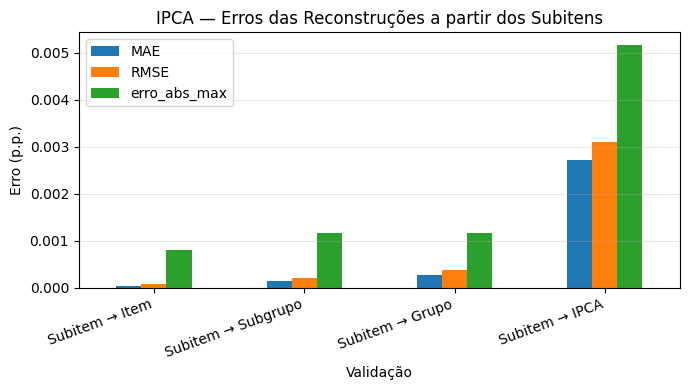

In [116]:
metricas_plot = (
    metricas
    .set_index("validacao")
    [
        [
            "MAE",
            "RMSE",
            "erro_abs_max",
        ]
    ]
)

ax = metricas_plot.plot(
    kind="bar",
    figsize=(7, 4),
)

ax.set_title(
    "IPCA — Erros das Reconstruções a partir dos Subitens"
)

ax.set_xlabel("Validação")
ax.set_ylabel("Erro (p.p.)")

plt.xticks(
    rotation=20,
    ha="right",
)

plt.grid(
    True,
    axis="y",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

### 20. Maiores erros encontrados

In [102]:
validacoes = {
    "Subitem → Item":
    validacao_itens,

    "Subitem → Subgrupo":
    validacao_subgrupos,

    "Subitem → Grupo":
    validacao_grupos,

    "Subitem → IPCA":
    validacao_ipca,
}

for nome, dados in (
    validacoes.items()
):

    print(
        f"\n{nome.upper()}"
    )

    display(
        dados.nlargest(
            10,
            "erro_abs",
        )
    )


SUBITEM → ITEM


,date,item_codigo,item_nome,contribuicao_publicada,contribuicao_reconstruida,erro,erro_abs
3044,2024-12-01,5102,Veículo próprio,0.020649,0.019847,-0.000801,0.000801
2279,2023-09-01,5102,Veículo próprio,0.046012,0.045304,-0.000708,0.000708
800,2021-04-01,5102,Veículo próprio,0.040703,0.041366,0.000663,0.000663
1955,2023-03-01,2101,Aluguel e taxas,0.006117,0.005480,-0.000637,0.000637
3452,2025-08-01,5102,Veículo próprio,0.000000,0.000626,0.000626,0.000626
2993,2024-11-01,5102,Veículo próprio,0.029864,0.029243,-0.000621,0.000621
86,2020-02-01,5102,Veículo próprio,0.022378,0.021776,-0.000602,0.000602
1259,2022-01-01,5102,Veículo próprio,0.216335,0.215750,-0.000585,0.000585
2228,2023-08-01,5102,Veículo próprio,0.089200,0.088616,-0.000584,0.000584
1209,2021-12-01,5104,Combustíveis (veículos),-0.075200,-0.074651,0.000549,0.000549



SUBITEM → SUBGRUPO


,date,subgrupo_codigo,subgrupo_nome,contribuicao_publicada,contribuicao_reconstruida,erro,erro_abs
1512,2026-08-01,51,Transportes,-0.174319,-0.173142,0.001177,0.001177
714,2023-02-01,51,Transportes,0.075639,0.074520,-0.001119,0.001119
391,2021-09-01,51,Transportes,0.382098,0.381076,-0.001022,0.001022
847,2023-09-01,51,Transportes,0.289589,0.290606,0.001018,0.001018
638,2022-10-01,51,Transportes,0.118514,0.119483,0.000968,0.000968
809,2023-07-01,51,Transportes,0.305745,0.304778,-0.000967,0.000967
30,2020-02-01,51,Transportes,-0.047430,-0.046486,0.000944,0.000944
1056,2024-08-01,51,Transportes,0.000000,0.000929,0.000929,0.000929
1246,2025-06-01,51,Transportes,0.055072,0.054154,-0.000918,0.000918
315,2021-05-01,51,Transportes,0.238306,0.239203,0.000896,0.000896



SUBITEM → GRUPO


,date,grupo_codigo,grupo_nome,contribuicao_publicada,contribuicao_reconstruida,erro,erro_abs
715,2026-08-01,5,Transportes,-0.174319,-0.173142,0.001177,0.001177
387,2023-08-01,1,Alimentação e bebidas,-0.181445,-0.182600,-0.001155,0.001155
18,2020-03-01,1,Alimentação e bebidas,0.218706,0.217559,-0.001147,0.001147
337,2023-02-01,5,Transportes,0.075639,0.074520,-0.001119,0.001119
585,2025-06-01,1,Alimentação e bebidas,-0.039473,-0.040587,-0.001114,0.001114
378,2023-07-01,1,Alimentação e bebidas,-0.098775,-0.099888,-0.001112,0.001112
81,2020-10-01,1,Alimentação e bebidas,0.395308,0.394204,-0.001105,0.001105
505,2024-09-01,2,Habitação,0.273267,0.272178,-0.001089,0.001089
351,2023-04-01,1,Alimentação e bebidas,0.153305,0.154362,0.001057,0.001057
184,2021-09-01,5,Transportes,0.382098,0.381076,-0.001022,0.001022



SUBITEM → IPCA


,date,ipca_oficial,ipca_reconstruido,erro,erro_abs
46,2023-11-01,0.280000,0.274827,-0.005173,0.005173
2,2020-03-01,0.070000,0.065057,-0.004943,0.004943
8,2020-09-01,0.640000,0.635066,-0.004934,0.004934
33,2022-10-01,0.590000,0.594821,0.004821,0.004821
62,2025-03-01,0.560000,0.564771,0.004771,0.004771
74,2026-03-01,0.880000,0.875233,-0.004767,0.004767
49,2024-02-01,0.830000,0.825266,-0.004734,0.004734
76,2026-05-01,0.580000,0.584716,0.004716,0.004716
60,2025-01-01,0.160000,0.155374,-0.004626,0.004626
32,2022-09-01,-0.290000,-0.285417,0.004583,0.004583


---

## PARTE IV: ESTABILIDADE TEMPORAL



### 21. Erro Subitem → IPCA

A reconstrução final é a validação mais importante:

$$
\widehat{\pi}^{SI}_t\quad\text{versus}\quad\pi_t
$$

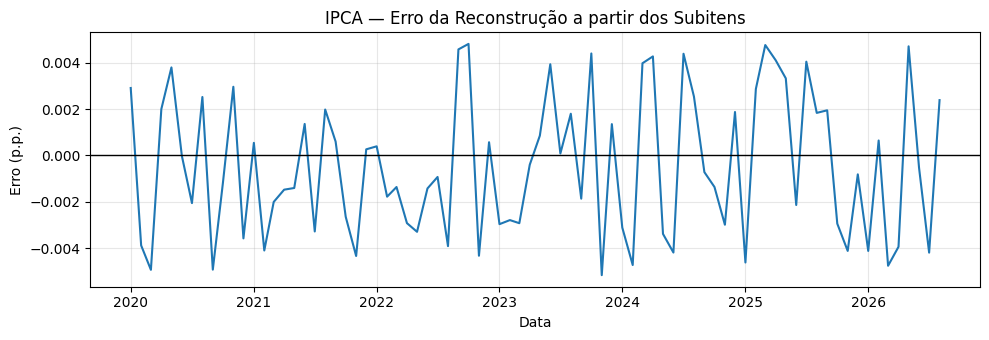

In [117]:
plt.figure(figsize=(10, 3.5))

plt.plot(
    validacao_ipca["date"],
    validacao_ipca["erro"],
)

plt.axhline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    "IPCA — Erro da Reconstrução a partir dos Subitens"
)

plt.xlabel("Data")
plt.ylabel("Erro (p.p.)")

plt.grid(
    True,
    alpha=0.3,
)

plt.tight_layout()
plt.show()

### 22. Erro absoluto

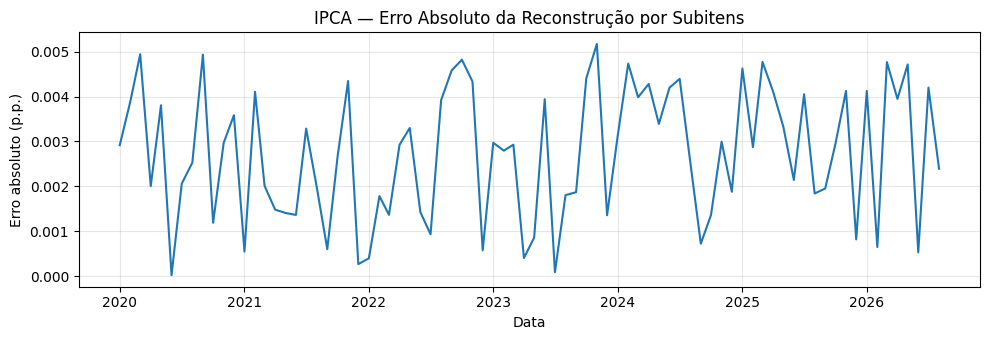

In [118]:
plt.figure(figsize=(10, 3.5))

plt.plot(
    validacao_ipca["date"],
    validacao_ipca["erro_abs"],
)

plt.title(
    "IPCA — Erro Absoluto da Reconstrução por Subitens"
)

plt.xlabel("Data")
plt.ylabel("Erro absoluto (p.p.)")

plt.grid(
    True,
    alpha=0.3,
)

plt.tight_layout()
plt.show()

### 23. Erro absoluto médio móvel

Para verificar se existem períodos prolongados de maior divergência:

$$
\overline{E}^{(12)}_t=\frac{1}{12}\sum_{j=0}^{11} E_{t-j}
$$

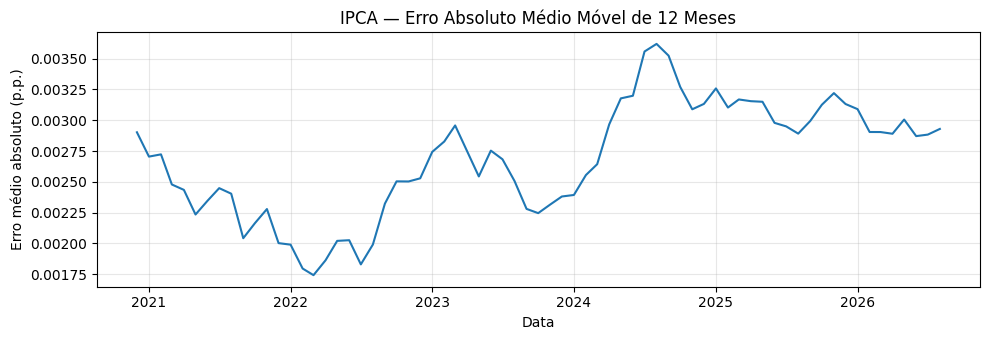

In [119]:
validacao_ipca[
    "erro_abs_mm12"
] = (
    validacao_ipca[
        "erro_abs"
    ]
    .rolling(12)
    .mean()
)

plt.figure(figsize=(10, 3.5))

plt.plot(
    validacao_ipca["date"],
    validacao_ipca[
        "erro_abs_mm12"
    ],
)

plt.title(
    "IPCA — Erro Absoluto Médio Móvel de 12 Meses"
)

plt.xlabel("Data")
plt.ylabel("Erro médio absoluto (p.p.)")

plt.grid(
    True,
    alpha=0.3,
)

plt.tight_layout()
plt.show()

### 24. Meses de maior divergência

In [120]:
validacao_ipca.nlargest(
    15,
    "erro_abs",
)[
    [
        "date",
        "ipca_oficial",
        "ipca_reconstruido",
        "erro",
        "erro_abs",
    ]
]

,date,ipca_oficial,ipca_reconstruido,erro,erro_abs
46,2023-11-01,0.280000,0.274827,-0.005173,0.005173
2,2020-03-01,0.070000,0.065057,-0.004943,0.004943
8,2020-09-01,0.640000,0.635066,-0.004934,0.004934
33,2022-10-01,0.590000,0.594821,0.004821,0.004821
62,2025-03-01,0.560000,0.564771,0.004771,0.004771
74,2026-03-01,0.880000,0.875233,-0.004767,0.004767
49,2024-02-01,0.830000,0.825266,-0.004734,0.004734
76,2026-05-01,0.580000,0.584716,0.004716,0.004716
60,2025-01-01,0.160000,0.155374,-0.004626,0.004626
32,2022-09-01,-0.290000,-0.285417,0.004583,0.004583


---

## PARTE V: RESULTADO ATUAL



### 25. Último mês disponível

In [107]:
ultimo_mes = (
    validacao_ipca[
        "date"
    ]
    .max()
)

ultimo_mes

Timestamp('2026-08-01 00:00:00')

### 26. IPCA reconstruído versus oficial

In [108]:
validacao_ipca[
    validacao_ipca["date"]
    == ultimo_mes
]

,date,ipca_oficial,ipca_reconstruido,erro,erro_abs,erro_abs_mm12
79,2026-08-01,-0.320000,-0.317609,0.002391,0.002391,0.002930


### 27. Consistência nos níveis superiores

Para o último mês, mostramos o maior erro encontrado em cada
nível de agregação.

In [109]:
def maior_erro_mes(
    dados,
    mes,
):

    dados_mes = dados[
        dados["date"] == mes
    ]

    if dados_mes.empty:
        return np.nan

    return dados_mes[
        "erro_abs"
    ].max()

In [110]:
resumo_atual = pd.DataFrame(
    [
        {
            "validacao":
            "Subitem → Item",

            "erro_abs_max":
            maior_erro_mes(
                validacao_itens,
                ultimo_mes,
            ),
        },
        {
            "validacao":
            "Subitem → Subgrupo",

            "erro_abs_max":
            maior_erro_mes(
                validacao_subgrupos,
                ultimo_mes,
            ),
        },
        {
            "validacao":
            "Subitem → Grupo",

            "erro_abs_max":
            maior_erro_mes(
                validacao_grupos,
                ultimo_mes,
            ),
        },
        {
            "validacao":
            "Subitem → IPCA",

            "erro_abs_max":
            maior_erro_mes(
                validacao_ipca,
                ultimo_mes,
            ),
        },
    ]
)

resumo_atual

,validacao,erro_abs_max
0,Subitem → Item,0.000239
1,Subitem → Subgrupo,0.001177
2,Subitem → Grupo,0.001177
3,Subitem → IPCA,0.002391


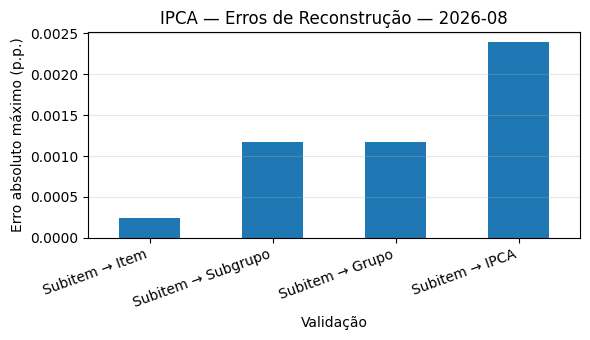

In [123]:
ax = (
    resumo_atual
    .set_index("validacao")[
        "erro_abs_max"
    ]
    .plot(
        kind="bar",
        figsize=(6, 3.5),
    )
)

ax.set_title(
    f"IPCA — Erros de Reconstrução — {ultimo_mes:%Y-%m}"
)

ax.set_xlabel("Validação")
ax.set_ylabel("Erro absoluto máximo (p.p.)")

plt.xticks(
    rotation=20,
    ha="right",
)

plt.grid(
    True,
    axis="y",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

---

### 28. Interpretação metodológica

O notebook utiliza uma única origem para toda a validação: ```SUBITENS```

A partir deles testamos:

* subitens → itens
* subitens → subgrupos
* subitens → grupos
* subitens → IPCA


Isso permite separar duas perguntas.

* **Consistência hierárquica**  
As contribuições dos subitens reproduzem adequadamente os níveis
agregados publicados?

* **Consistência com o agregado**  
A soma das contribuições dos subitens reproduz adequadamente o
IPCA geral publicado?

### 29. O que não estamos validando aqui

Este notebook não pretende reconstruir historicamente a metodologia
completa de formação dos pesos.

Utilizamos:

```text
    índice publicado
           +
     peso publicado
```

para cada subitem.

Portanto, validamos a consistência empírica da decomposição disponível,
não a origem metodológica histórica de cada ponderação.

### 30. Contribuição versus impacto

Para reconstrução utilizamos:

$$
C_{i,t}=\pi_{i,t}\frac{w_{i,t}}{100}
$$

O impacto:

$$
I_{i,t}=|C_{i,t}|
$$

permanece importante para análise de pressão, mas não participa
diretamente desta validação.

Isso reforça:

* contribuição $\to\qquad$ reconstrução
* impacto $\to\qquad$ análise de pressão


### 31. Conclusões

Este notebook validou a decomposição do IPCA utilizando os subitens
como origem única.

Foram avaliadas quatro relações:

$$
subitem\rightarrow item
$$

$$
subitem\rightarrow subgrupo
$$

$$
subitem \rightarrow grupo
$$

$$
subitem\rightarrow IPCA
$$

Para cada nível foram avaliados:

$$
ME,\quad MAE,\quad RMSE,\quad E_{max}
$$

A principal validação é:

$$
\widehat{\pi}^{SI}_t=\sum_i\left(\pi_{i,t}\frac{w_{i,t}}{100}\right)
$$

comparada ao IPCA oficialmente publicado:

$$
\pi_t
$$

Se os erros forem pequenos e estáveis, temos evidência empírica de
elevada consistência entre o nível mais granular disponível e a
estrutura agregada do IPCA.

---



### Próxima etapa

Com a estrutura validada, o próximo notebook deixa de perguntar:

> A decomposição fecha?

e passa a perguntar:

> Qual é a natureza do processo inflacionário?

Em:

```text
04.ipca_dinamica_inflacionaria
```

analisaremos:

- difusão;
- variação da difusão;
- dispersão;
- concentração;
- aceleração;
- persistência;
- medidas experimentais de inflação subjacente.